In [77]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("battery_observations.csv", index_col=0)
meta = pd.read_csv("battery_metadata.csv", index_col=0)
df2 = df.join(meta[["climate_zone", "chemistry"]])
df2 = df2.sort_values(["battery_id", "cycle_index"])
df2 = df2.reset_index()
meta = meta.reset_index()
g = lambda x: int(x.split('-')[-1])
df2["battery_id"] = df2["battery_id"].apply(g)
meta["battery_id"] = meta["battery_id"].apply(g)
battery_ids = list(set(df2["battery_id"]))
materials = list(set(meta["chemistry"]))
climate_zones = list(set(meta["climate_zone"]))
labels = list(set(df2["degradation_status"]))





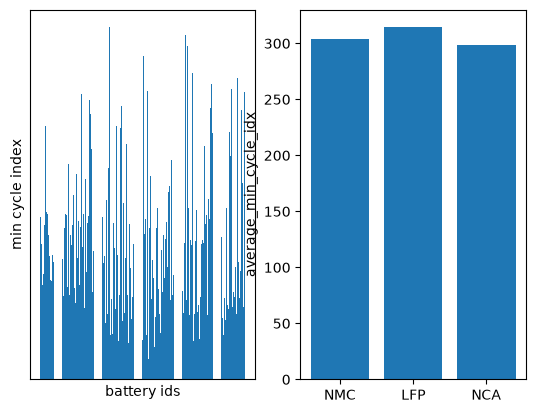

In [78]:
values = np.zeros_like(battery_ids)
for i,bi in enumerate(battery_ids):
    rel = df2[(df2["battery_id"] == bi) & (df2["degradation_status"] != "Normal")]
    values[i] = rel["cycle_index"].min()

values_materials = np.zeros_like(materials, dtype=int)
material_mapping = {x: t for x,t in zip(materials, range(3))}
counts = np.zeros_like(materials, dtype=int)
for k,v in zip(battery_ids, values):
    mat = meta.loc[meta["battery_id"] == k, "chemistry"].iloc[0]
    values_materials[material_mapping[mat]] += v
    counts[material_mapping[mat]] += 1

fig, ax = plt.subplots(1, 2)
ax[0].bar(battery_ids, values)
ax[1].bar(materials, values_materials / counts)
ax[0].set_xlabel("battery ids")
ax[0].set_ylabel("min cycle index")
ax[0].tick_params(bottom=False, labelbottom=False)
ax[0].tick_params(left=False, labelleft=False)
ax[1].set_ylabel("average_min_cycle_idx")



plt.show()
    

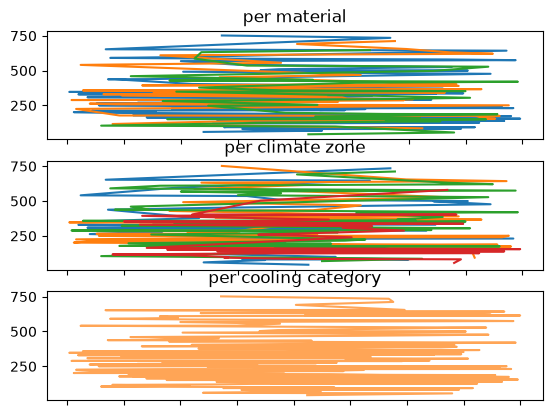

In [79]:
fig, ax = plt.subplots(3)
x = df2[df2["degradation_status"] != "Normal"].groupby(["battery_id"])["cycle_index"].min().reset_index()
colors = ["C0", "C1", "C2"]
for i,m in enumerate(materials):
    y = x[x["battery_id"].isin(meta[meta["chemistry"] == m].index)].sort_values("cycle_index")
    ax[0].plot(y["battery_id"], y["cycle_index"], color=colors[i])

colors = ["C0", "C1", "C2", "C3"]

for i,m in enumerate(climate_zones):
    y = x[x["battery_id"].isin(meta[meta["climate_zone"] == m].index)].sort_values("cycle_index")
    ax[1].plot(y["battery_id"], y["cycle_index"], color=colors[i])

y1 = x[x["battery_id"].isin(df2[df2["cooling_active"] == True].index)].sort_values("cycle_index")
y2 = x[x["battery_id"].isin(df2[df2["cooling_active"] == False].index)].sort_values("cycle_index")

ax[2].plot(y1["battery_id"], y1["cycle_index"], color="C0", alpha=0.7)
ax[2].plot(y2["battery_id"], y2["cycle_index"], color="C1", alpha=0.7)

ax[0].set_title("per material")
ax[0].tick_params(labelbottom=False)

ax[1].set_title("per climate zone")
ax[1].tick_params(labelbottom=False)

ax[2].set_title("per cooling category")
ax[2].tick_params(labelbottom=False)


plt.show()
    

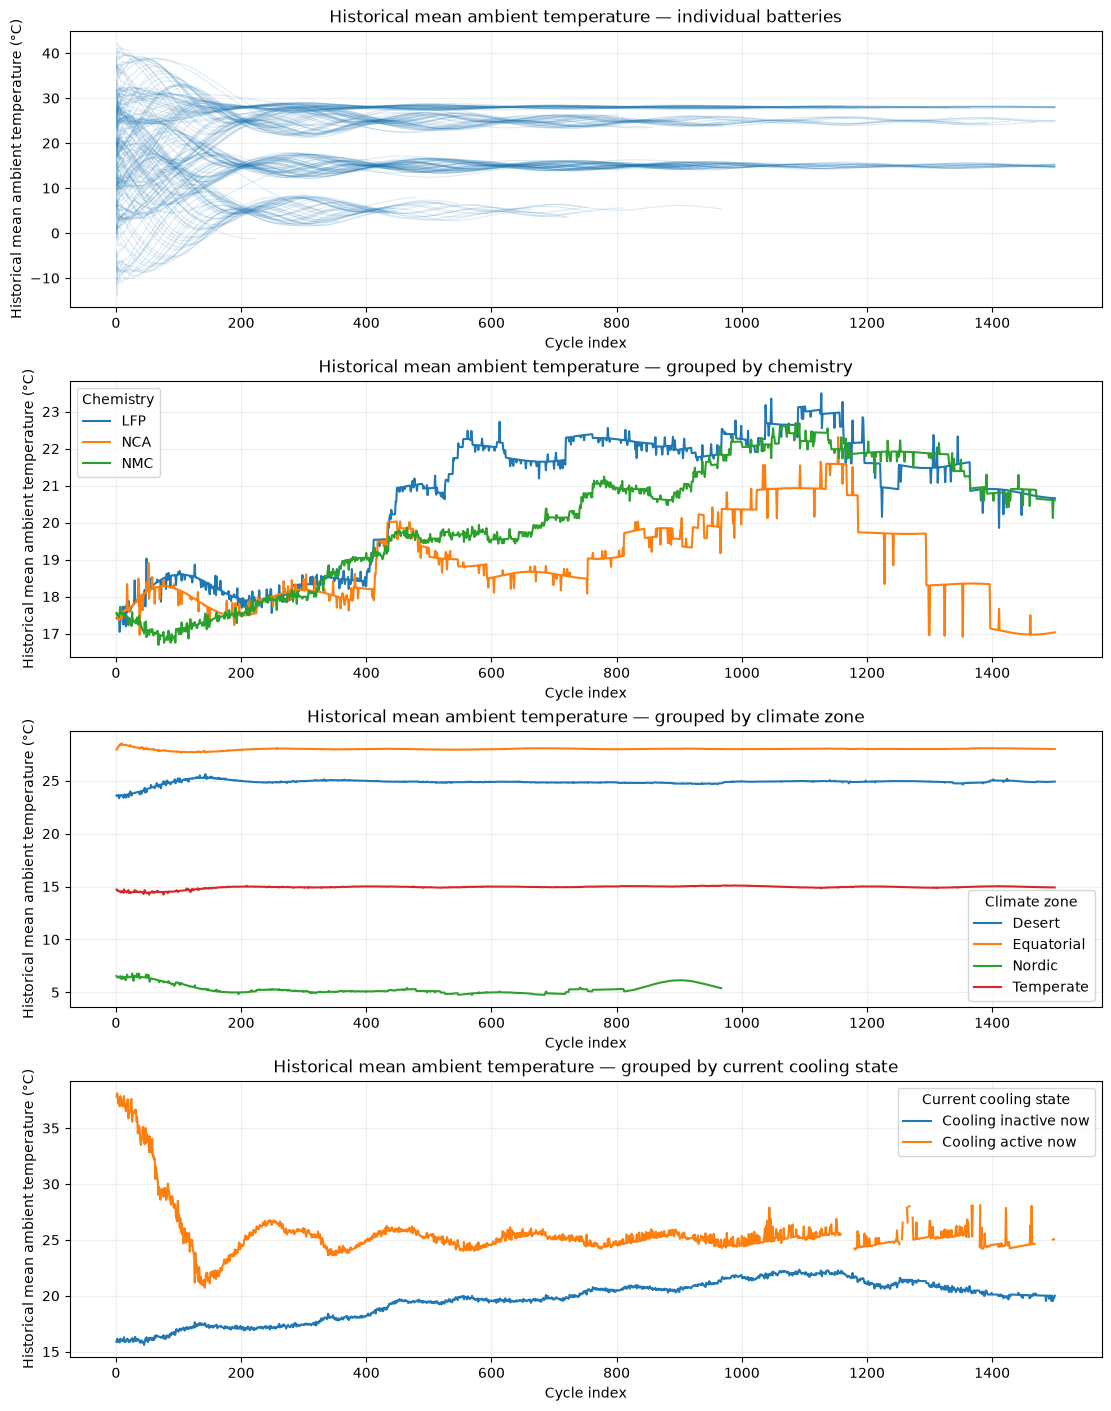

In [121]:
import matplotlib.pyplot as plt

# Assumes one row per battery and cycle.
df2 = (
    df2.sort_values(["battery_id", "cycle_index"])
       .copy()
)

# Average observed ambient temperature through the current cycle.
df2["mean_ambient_temp_so_far"] = (
    df2.groupby("battery_id")["ambient_temp_c"]
       .transform(lambda s: s.expanding(min_periods=1).mean())
)

fig, axes = plt.subplots(
    4, 1,
    figsize=(11, 14),
    layout="constrained"
)

# 1. Individual battery trajectories.
for bi, subset in df2.groupby("battery_id"):
    axes[0].plot(
        subset["cycle_index"],
        subset["mean_ambient_temp_so_far"],
        color="C0",
        alpha=0.15,
        linewidth=0.8
    )

axes[0].set_title(
    "Historical mean ambient temperature — individual batteries"
)

# 2–4. Average historical means within each group.
groupings = [
    (
        "chemistry",
        axes[1],
        "Historical mean ambient temperature — grouped by chemistry",
        "Chemistry"
    ),
    (
        "climate_zone",
        axes[2],
        "Historical mean ambient temperature — grouped by climate zone",
        "Climate zone"
    ),
    (
        "cooling_active",
        axes[3],
        "Historical mean ambient temperature — grouped by current cooling state",
        "Current cooling state"
    ),
]

for group_column, ax, title, legend_title in groupings:
    mean_curves = (
        df2.groupby([group_column, "cycle_index"])[
            "mean_ambient_temp_so_far"
        ]
        .mean()
        .unstack(level=0)
        .sort_index()
    )

    for group in mean_curves.columns:
        label = str(group)

        if group_column == "cooling_active":
            label = (
                "Cooling active now"
                if bool(group)
                else "Cooling inactive now"
            )

        ax.plot(
            mean_curves.index,
            mean_curves[group],
            label=label,
            linewidth=1.5
        )

    ax.set_title(title)
    ax.legend(title=legend_title)

for ax in axes:
    ax.set_xlabel("Cycle index")
    ax.set_ylabel("Historical mean ambient temperature (°C)")
    ax.grid(alpha=0.2)

plt.show()

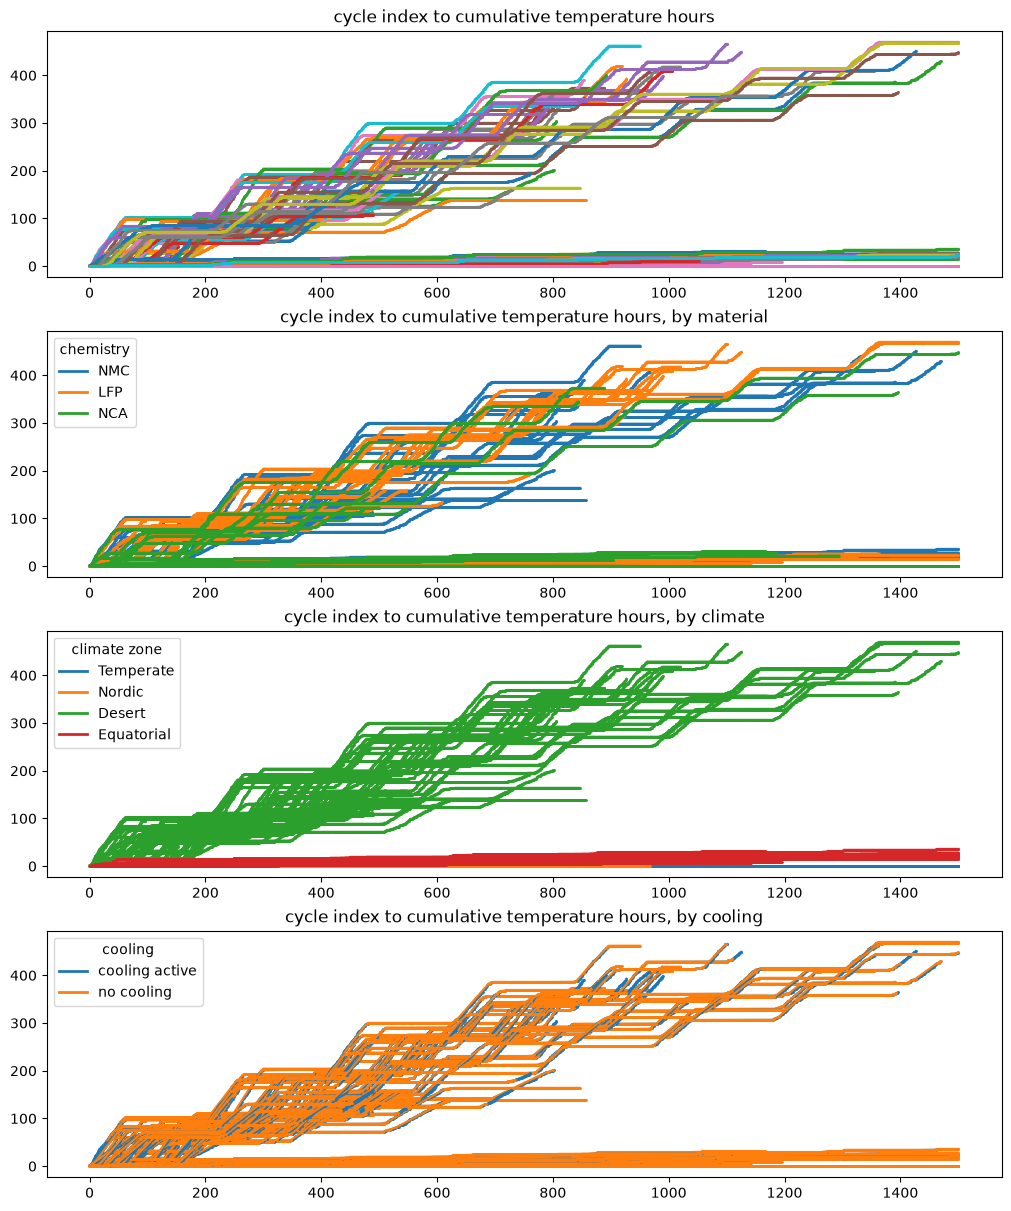

In [ ]:
"""
cumulative high temp hours vs. cycle index:
1. all
2. per material group
3. per climate group
"""


import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def add_color_legend(a, color_map, title=None):
    handles = [Line2D([0], [0], color=c, lw=2, label=str(k)) for k, c in color_map.items()]
    a.legend(handles=handles, title=title, loc="upper left")

fig, ax = plt.subplots(4, figsize=(10, 12), layout="constrained")

# 1. all batteries (no color grouping, so no legend)
for bi in battery_ids:
    x = df2[df2["battery_id"] == bi].sort_values("cycle_index")
    ax[0].plot(x["cycle_index"], x["cumulative_high_temp_hours"], marker="o", markersize=1)

# 2. by material
mat_colors = {m: f"C{i}" for i, m in enumerate(materials)}
for m in materials:
    x = df2[df2["chemistry"] == m]
    for bi in battery_ids:
        y = x[x["battery_id"] == bi].sort_values("cycle_index")
        ax[1].plot(y["cycle_index"], y["cumulative_high_temp_hours"],
                   color=mat_colors[m], marker="o", markersize=1)
add_color_legend(ax[1], mat_colors, title="chemistry")

# 3. by climate zone
climate_colors = {m: f"C{i}" for i, m in enumerate(climate_zones)}
for m in climate_zones:
    x = df2[df2["climate_zone"] == m]
    for bi in battery_ids:
        y = x[x["battery_id"] == bi].sort_values("cycle_index")
        ax[2].plot(y["cycle_index"], y["cumulative_high_temp_hours"],
                   color=climate_colors[m], marker="o", markersize=1)
add_color_legend(ax[2], climate_colors, title="climate zone")

# 4. by cooling
cooling_colors = {"cooling active": "C0", "no cooling": "C1"}
for bi in battery_ids:
    x = df2[df2["battery_id"] == bi].sort_values("cycle_index")
    x1 = x[x["cooling_active"] == True]
    x2 = x[x["cooling_active"] == False]
    ax[3].plot(x1["cycle_index"], x1["cumulative_high_temp_hours"],
               color=cooling_colors["cooling active"], marker="o", markersize=1)
    ax[3].plot(x2["cycle_index"], x2["cumulative_high_temp_hours"],
               color=cooling_colors["no cooling"], marker="o", markersize=1)
add_color_legend(ax[3], cooling_colors, title="cooling")

ax[0].set_title("cycle index to cumulative temperature hours")
ax[1].set_title("cycle index to cumulative temperature hours, by material")
ax[2].set_title("cycle index to cumulative temperature hours, by climate")
ax[3].set_title("cycle index to cumulative temperature hours, by cooling")

plt.show()

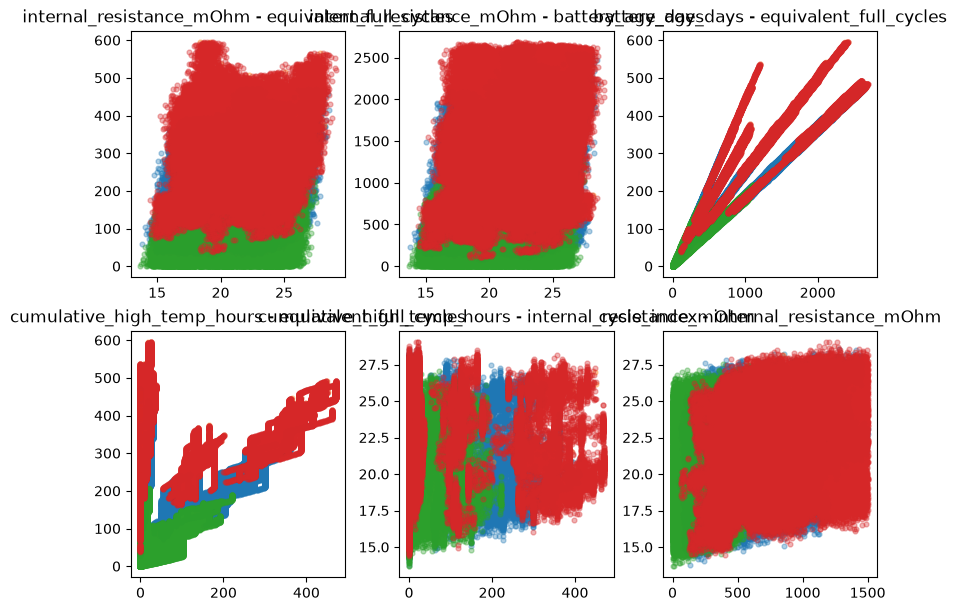

In [ ]:
fig, ax = plt.subplots(2, 3, figsize=(8, 6), layout="constrained")
variables = [
    ["internal_resistance_mOhm", "equivalent_full_cycles"],
    ["internal_resistance_mOhm", "battery_age_days"],
    ["battery_age_days", "equivalent_full_cycles"],
    ["cumulative_high_temp_hours", "equivalent_full_cycles"],
    ["cumulative_high_temp_hours", "internal_resistance_mOhm"],
    ["cycle_index", "internal_resistance_mOhm"],
]
colors = [f"C{k}" for k in range(4)]
c = 0
for i in range(2):
    for j in range(3):
        for label, color in zip(labels, colors):
            subset = df2[df2["degradation_status"] == label]
            ax[i,j].scatter(
                subset[variables[c][0]],
                subset[variables[c][1]],
                s=12,
                alpha=0.35,
                color=color,
                label=label
            )
            ax[i,j].set_title(f"{variables[c][0]} - {variables[c][1]}")
        c += 1

plt.show()

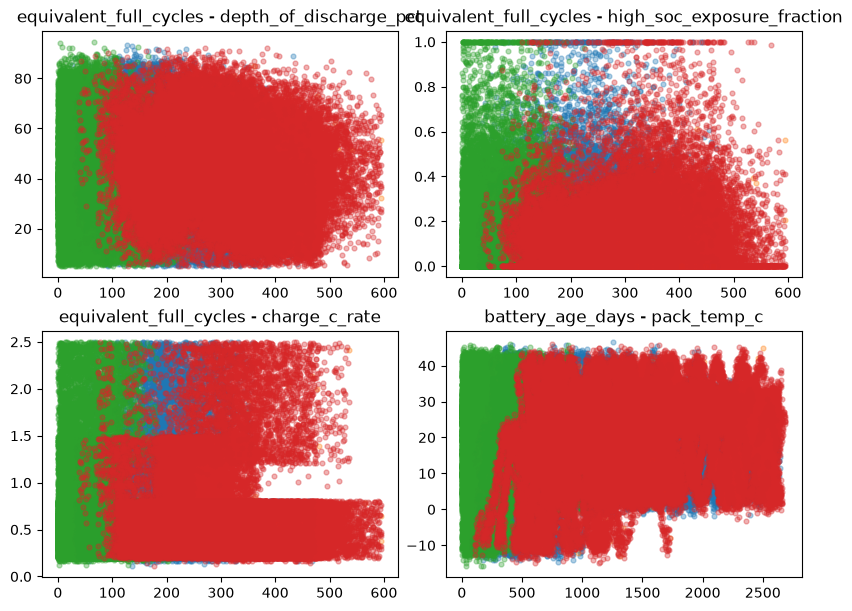

In [107]:
fig, ax = plt.subplots(2, 2, figsize=(8, 6), layout="constrained")
variables = [
    ["equivalent_full_cycles", "depth_of_discharge_pct"],
    ["equivalent_full_cycles", "high_soc_exposure_fraction"],
    ["equivalent_full_cycles", "charge_c_rate"],
    ["battery_age_days", "pack_temp_c"],
]
colors = [f"C{k}" for k in range(4)]
c = 0
for i in range(2):
    for j in range(2):
        for label, color in zip(labels, colors):
            subset = df2[df2["degradation_status"] == label]
            ax[i,j].scatter(
                subset[variables[c][0]],
                subset[variables[c][1]],
                s=12,
                alpha=0.35,
                color=color,
                label=label
            )
            ax[i,j].set_title(f"{variables[c][0]} - {variables[c][1]}")
        c += 1

plt.show()

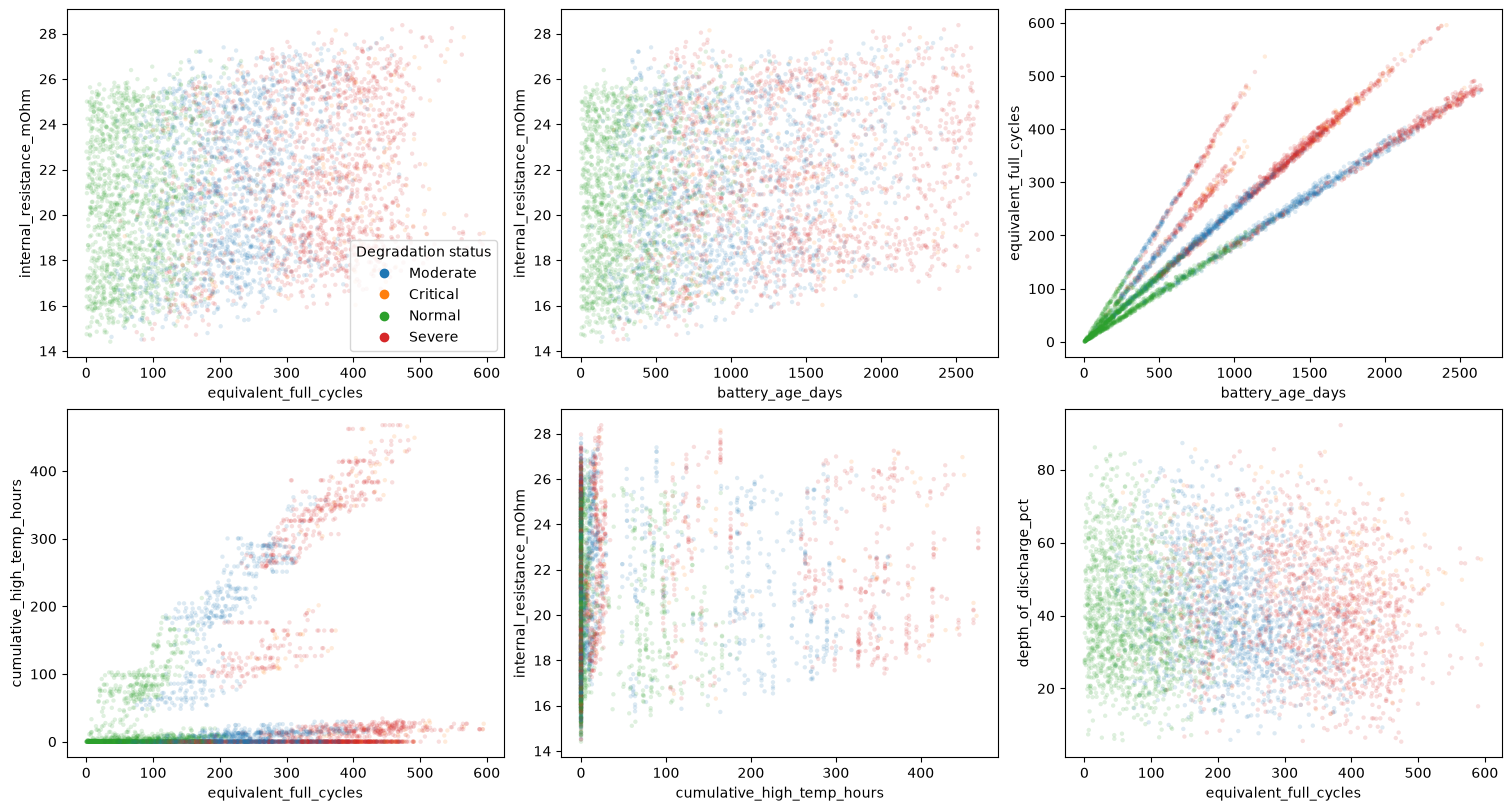

In [109]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

variables = [
    ("equivalent_full_cycles", "internal_resistance_mOhm"),
    ("battery_age_days", "internal_resistance_mOhm"),
    ("battery_age_days", "equivalent_full_cycles"),
    ("equivalent_full_cycles", "cumulative_high_temp_hours"),
    ("cumulative_high_temp_hours", "internal_resistance_mOhm"),
    ("equivalent_full_cycles", "depth_of_discharge_pct"),
]

labels = list(labels)
palette = {
    label: f"C{i % 10}"
    for i, label in enumerate(labels)
}

# Balanced sample for visualization only.
parts = []
for label in labels:
    subset = df2.loc[df2["degradation_status"].eq(label)]
    parts.append(
        subset.sample(n=min(1500, len(subset)), random_state=42)
    )

plot_df = (
    pd.concat(parts)
      .sample(frac=1, random_state=42)
)

point_colors = plot_df["degradation_status"].map(palette)

fig, axes = plt.subplots(
    2, 3, figsize=(15, 8), layout="constrained"
)

for ax, (x, y) in zip(axes.flat, variables):
    ax.scatter(
        plot_df[x],
        plot_df[y],
        c=point_colors,
        s=10,
        alpha=0.15,
        linewidths=0
    )

    ax.set_xlabel(x)
    ax.set_ylabel(y)

handles = [
    plt.Line2D(
        [], [], linestyle="",
        marker="o", color=palette[label], label=label
    )
    for label in labels
]

axes.flat[0].legend(handles=handles, title="Degradation status")
plt.show()

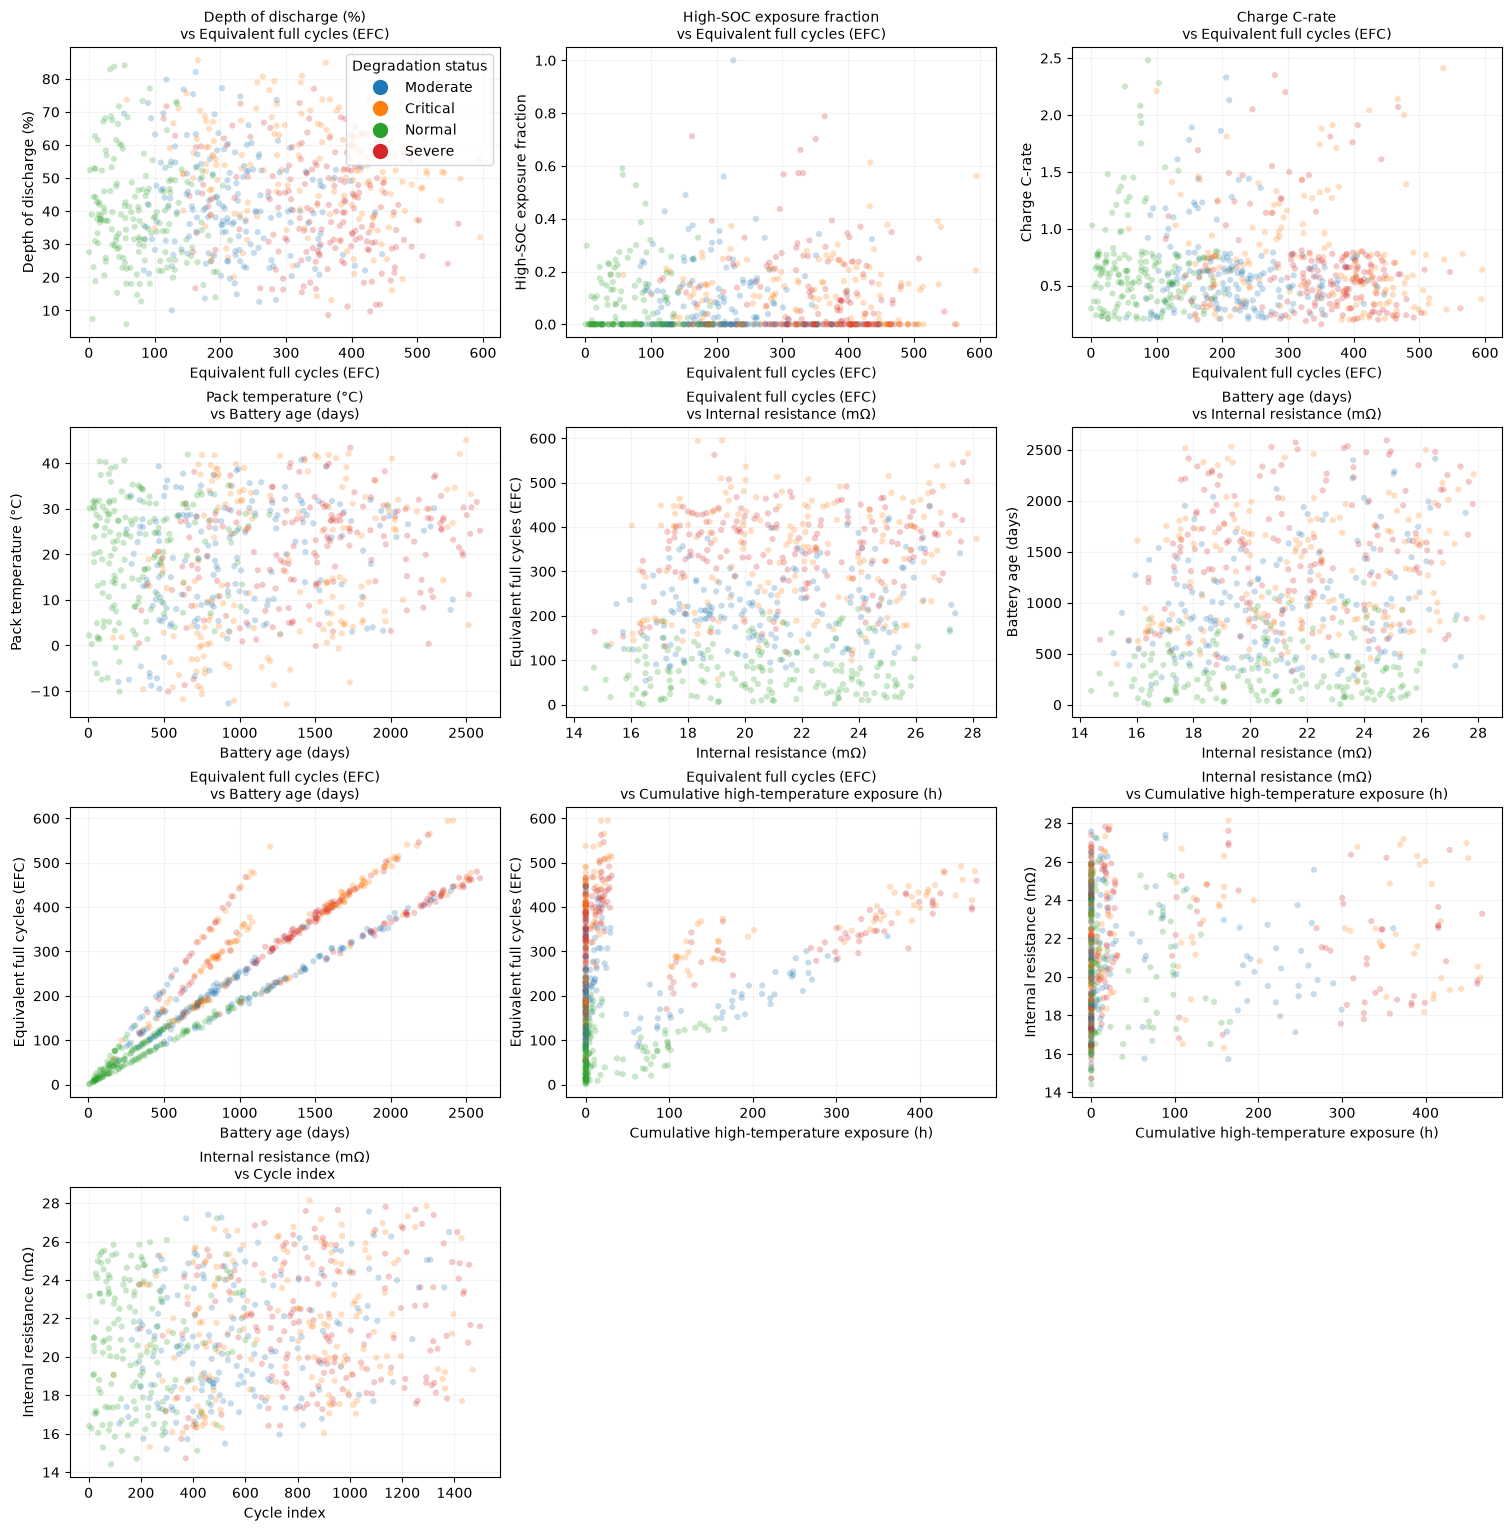

In [ ]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# Each tuple is (x-axis, y-axis).
variables = [
    # Operating conditions versus accumulated usage
    ("equivalent_full_cycles", "depth_of_discharge_pct"),
    ("equivalent_full_cycles", "high_soc_exposure_fraction"),
    ("equivalent_full_cycles", "charge_c_rate"),
    ("battery_age_days", "pack_temp_c"),

    # Accumulated usage, age, and health indicators
    ("internal_resistance_mOhm", "equivalent_full_cycles"),
    ("internal_resistance_mOhm", "battery_age_days"),
    ("battery_age_days", "equivalent_full_cycles"),
    ("cumulative_high_temp_hours", "equivalent_full_cycles"),
    ("cumulative_high_temp_hours", "internal_resistance_mOhm"),
    ("cycle_index", "internal_resistance_mOhm"),
]


# Use your existing label order.
labels = list(labels)

palette = {
    label: f"C{i % 10}"
    for i, label in enumerate(labels)
}


# Take the same number of rows from each non-empty class.
# Unlike a separate min(1500, len(subset)) for each class,
# this produces an exactly balanced visualization sample.
class_counts = (
    df2.loc[df2["degradation_status"].isin(labels), "degradation_status"]
       .value_counts()
)

if class_counts.empty:
    raise ValueError("No rows match the supplied degradation-status labels.")

n_per_class = min(1500, int(class_counts.min()))

parts = []
for label in labels:
    subset = df2.loc[df2["degradation_status"].eq(label)]

    if subset.empty:
        continue

    parts.append(
        subset.sample(n=n_per_class, random_state=42)
    )

# Shuffle so no single class is consistently drawn on top.
plot_df = (
    pd.concat(parts)
      .sample(frac=1, random_state=42)
)


# Optional: more readable axis labels.
axis_labels = {
    "equivalent_full_cycles": "Equivalent full cycles (EFC)",
    "depth_of_discharge_pct": "Depth of discharge (%)",
    "high_soc_exposure_fraction": "High-SOC exposure fraction",
    "charge_c_rate": "Charge C-rate",
    "battery_age_days": "Battery age (days)",
    "pack_temp_c": "Pack temperature (°C)",
    "internal_resistance_mOhm": "Internal resistance (mΩ)",
    "cumulative_high_temp_hours": "Cumulative high-temperature exposure (h)",
    "cycle_index": "Cycle index",
}


# Create enough panels for any number of variable pairs.
ncols = 3
nrows = math.ceil(len(variables) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(5 * ncols, 3.8 * nrows),
    layout="constrained",
    squeeze=False
)


for ax, (x, y) in zip(axes.flat, variables):
    # Remove missing values separately for each pair.
    valid = plot_df[[x, y]].notna().all(axis=1)
    subset = plot_df.loc[valid]

    ax.scatter(
        subset[x],
        subset[y],
        c=subset["degradation_status"].map(palette),
        s=20,
        alpha=0.25,
        linewidths=0
    )

    ax.set_xlabel(axis_labels.get(x, x))
    ax.set_ylabel(axis_labels.get(y, y))
    ax.set_title(
        f"{axis_labels.get(y, y)}\nvs {axis_labels.get(x, x)}",
        fontsize=10
    )
    ax.grid(alpha=0.15)


# Hide unused panels.
for ax in axes.flat[len(variables):]:
    ax.set_visible(False)


# Opaque legend markers remain readable despite transparent points.
handles = [
    Line2D(
        [], [],
        linestyle="",
        marker="o",
        markersize=10,
        color=palette[label],
        label=label
    )
    for label in labels
    if label in plot_df["degradation_status"].unique()
]

axes.flat[0].legend(
    handles=handles,
    title="Degradation status",
    loc="best"
)

plt.show()

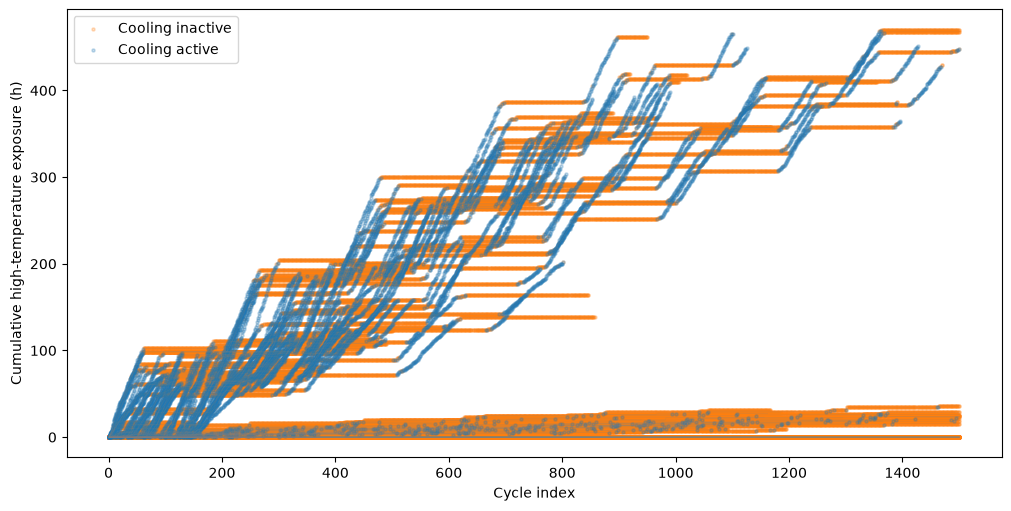

In [116]:
fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")

for bi, x in df2.groupby("battery_id"):
    x = x.sort_values("cycle_index")

    ax.plot(
        x["cycle_index"],
        x["cumulative_high_temp_hours"],
        color="grey",
        alpha=0.15,
        linewidth=0.7
    )

for active, color, label in [
    (False, "C1", "Cooling inactive"),
    (True, "C0", "Cooling active"),
]:
    subset = df2.loc[df2["cooling_active"].eq(active)]

    ax.scatter(
        subset["cycle_index"],
        subset["cumulative_high_temp_hours"],
        color=color,
        label=label,
        s=5,
        alpha=0.25
    )

ax.set_xlabel("Cycle index")
ax.set_ylabel("Cumulative high-temperature exposure (h)")
ax.legend()
plt.show()

In [ ]:
import pandas as pd

ordered = df2.sort_values(
    ["battery_id", "cycle_index"]
).copy()

# First recorded observation of each battery.
first_rows = ordered.drop_duplicates("battery_id", keep="first")

# Last recorded observation of each battery.
last_rows = ordered.drop_duplicates("battery_id", keep="last")

summary = (
    last_rows[
        [
            "battery_id",
            "chemistry",
            "climate_zone",
            "cycle_index",
            "battery_age_days",
            "equivalent_full_cycles",
        ]
    ]
    .rename(columns={
        "cycle_index": "last_observed_cycle",
        "battery_age_days": "last_observed_age_days",
        "equivalent_full_cycles": "last_observed_efc",
    })
    .set_index("battery_id")
)

non_normal = (
    ordered["degradation_status"].notna()
    & ordered["degradation_status"].ne("Normal")
)

first_non_normal = (
    ordered.loc[non_normal]
    .drop_duplicates("battery_id", keep="first")
    .set_index("battery_id")[
        [
            "cycle_index",
            "battery_age_days",
            "equivalent_full_cycles",
        ]
    ]
    .rename(columns={
        "cycle_index": "first_non_normal_cycle",
        "battery_age_days": "first_non_normal_age_days",
        "equivalent_full_cycles": "first_non_normal_efc",
    })
)

summary = summary.join(first_non_normal)

summary["non_normal_observed"] = (
    summary["first_non_normal_cycle"].notna()
)

summary["initial_status"] = (
    first_rows.set_index("battery_id")["degradation_status"]
)

summary["starts_normal"] = summary["initial_status"].eq("Normal")



NameError: name 'observed' is not defined

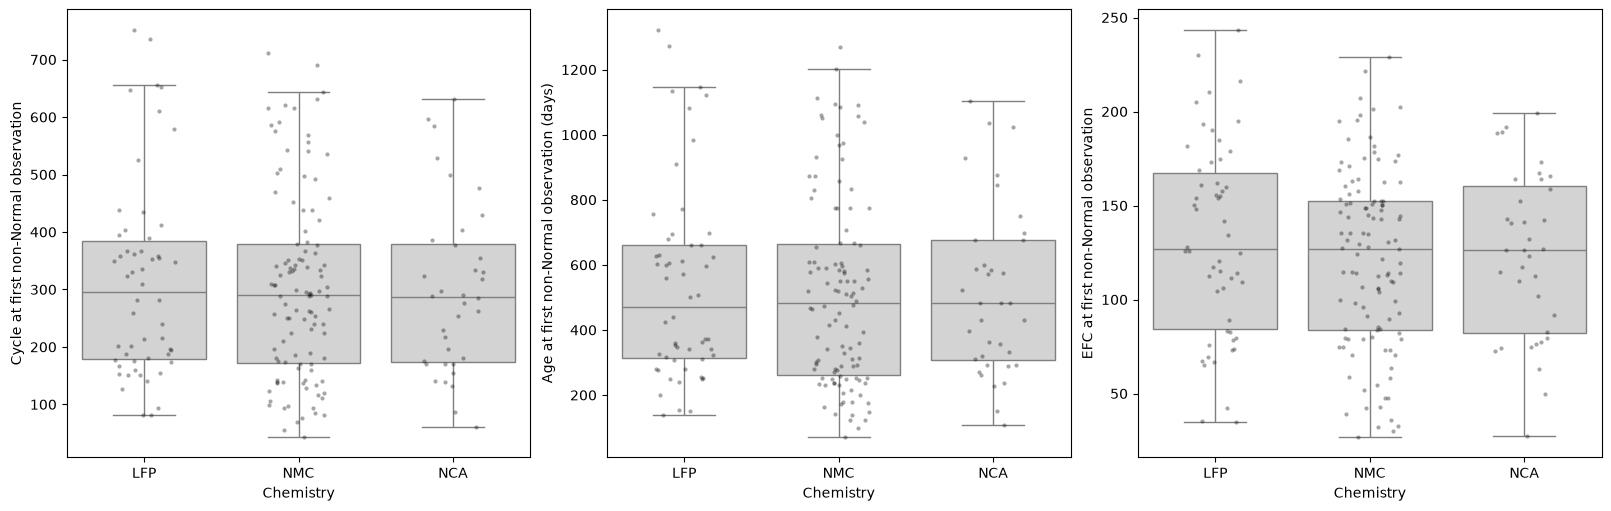

In [120]:
import seaborn as sns
import matplotlib.pyplot as plt

# Batteries with a recorded Normal state at entry
# and a later recorded non-Normal state.
observed = (
    summary.loc[
        summary["starts_normal"]
        & summary["non_normal_observed"]
    ]
    .reset_index()
)

outcomes = [
    ("first_non_normal_cycle", "Cycle at first non-Normal observation"),
    ("first_non_normal_age_days", "Age at first non-Normal observation (days)"),
    ("first_non_normal_efc", "EFC at first non-Normal observation"),
]

fig, axes = plt.subplots(
    1, 3, figsize=(16, 5), layout="constrained"
)

for ax, (column, ylabel) in zip(axes, outcomes):
    sns.boxplot(
        data=observed,
        x="chemistry",
        y=column,
        showfliers=False,
        color="lightgrey",
        ax=ax
    )

    sns.stripplot(
        data=observed,
        x="chemistry",
        y=column,
        color="black",
        alpha=0.35,
        size=3,
        jitter=0.2,
        ax=ax
    )

    ax.set_xlabel("Chemistry")
    ax.set_ylabel(ylabel)

plt.show()